# A multiplicative MMM with mixed dimensions

Ten products, five retailers, three product types, and inputs measured at different levels do not require fifty separate models.
Keep each input at its observed dimensions, compose its response with terms, and map product-type effects to products only when assembling log sales.

Read [Introduction to terms](introduction_terms.ipynb) first.
The [main experimental MMM example](experimental_mmm_api.ipynb) introduces fitting and prediction.
Run the cells in order; all data are generated locally.

> **Warning:** This API is experimental and its interfaces can change.
> The stable `MMM` class is unchanged.

| Block | Input dimensions, besides week | Response |
| --- | --- | --- |
| TV, social, video | Product type × retailer × media channel | Adstock → saturation |
| Search | Product type | Adstock → saturation |
| Two affiliates | Product type × retailer × affiliate channel | Adstock × coefficient; no saturation |
| Price and promotion controls | Product × retailer × control | Linear |
| Log sales | Product × retailer | Normal likelihood |

Products within a type share its media response.
Search has no retailer dimension, so its log effect is shared across retailers as well.
Baseline sales and control coefficients vary by product and retailer.
These are explicit pooling assumptions, not automatic causal identification.

## 1. Define the product hierarchy

Use named dimensions throughout, including separate dimensions for saturated media and unsaturated affiliates.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from pymc_extras.prior import Prior

from pymc_marketing.experimental.terms import SCM, Data, Equation
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.terms import Intercept, Parameter

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100

rng = np.random.default_rng(42)

In [2]:
products = [f"product_{i + 1:02d}" for i in range(10)]
retailers = [f"retailer_{i + 1}" for i in range(5)]
product_types = ["type_A", "type_B", "type_C"]
product_type_index = np.array([0, 0, 0, 0, 1, 1, 1, 2, 2, 2])
dates = pd.date_range("2023-01-02", periods=156, freq="W-MON")
coords = {
    "date": dates,
    "product": products,
    "retailer": retailers,
    "product_type": product_types,
    "media_channel": ["tv", "social", "video"],
    "affiliate_channel": ["affiliate_1", "affiliate_2"],
    "control": ["log_price_ratio", "centered_promotion"],
}
pd.Series(
    np.array(product_types)[product_type_index], index=products, name="Product type"
).to_frame()

,Product type
product_01,type_A
product_02,type_A
product_03,type_A
product_04,type_A
product_05,type_B
product_06,type_B
product_07,type_B
product_08,type_C
product_09,type_C
product_10,type_C


A one-hot membership matrix connects the three types to the ten products.
Each row contains exactly one 1.
Multiplying a type-level term by this matrix and summing `product_type` selects the correct type for each product; it does not sum all three types into every product.

The matrix records a fixed hierarchy, not an estimated sales allocation or a division of spend among products.

In [3]:
membership = xr.DataArray(
    np.eye(len(product_types))[product_type_index],
    dims=("product", "product_type"),
    coords={"product": products, "product_type": product_types},
)
membership.to_pandas()

product_type,type_A,type_B,type_C
product,,,
product_01,1.0,0.0,0.0
product_02,1.0,0.0,0.0
product_03,1.0,0.0,0.0
product_04,1.0,0.0,0.0
product_05,0.0,1.0,0.0
product_06,0.0,1.0,0.0
product_07,0.0,1.0,0.0
product_08,0.0,0.0,1.0
product_09,0.0,0.0,1.0


## 2. Simulate inputs at their native dimensions

Use 156 weeks of independently varying spend and controls so the example focuses on dimensions rather than confounding.
Spend is currency per week at the level where it is measured.
Price enters as `log(price / reference_price)`; promotion is a centered indicator.
The synthetic process starts with zero prehistory.

In [4]:
media_dims = ("date", "product_type", "retailer", "media_channel")
affiliate_dims = ("date", "product_type", "retailer", "affiliate_channel")
control_dims = ("date", "product", "retailer", "control")


def simulate_spend(dims: tuple[str, ...]) -> xr.DataArray:
    """Generate intermittent weekly spend at the supplied dimensions."""
    shape = tuple(len(coords[dim]) for dim in dims)
    values = rng.uniform(0, 1_000, size=shape) * (rng.random(shape) > 0.35)
    return xr.DataArray(values, dims=dims, coords={dim: coords[dim] for dim in dims})


control_shape = (len(dates), len(products), len(retailers))
log_price_ratio = rng.normal(0, 0.12, size=control_shape)
centered_promotion = rng.binomial(1, 0.25, size=control_shape) - 0.25
raw = xr.Dataset(
    {
        "media_spend": simulate_spend(media_dims),
        "search_spend": simulate_spend(("date", "product_type")),
        "affiliate_spend": simulate_spend(affiliate_dims),
        "controls": (
            control_dims,
            np.stack([log_price_ratio, centered_promotion], axis=-1),
        ),
        "membership": membership,
    },
    coords=coords,
)

Divide each spend input by a fixed reference of 1,000 currency units, without adding dimensions.
Reuse this reference for scenarios or forecasts.
The terms API performs no hidden scaling.
Controls already have meaningful reference units and stay unchanged.

In [5]:
spend_reference = 1_000.0
inputs = raw.assign(
    media_spend=raw["media_spend"] / spend_reference,
    search_spend=raw["search_spend"] / spend_reference,
    affiliate_spend=raw["affiliate_spend"] / spend_reference,
)
inputs

<xarray.Dataset> Size: 225kB
Dimensions:            (date: 156, product_type: 3, retailer: 5,
                        media_channel: 3, affiliate_channel: 2, product: 10,
                        control: 2)
Coordinates:
  * date               (date) datetime64[us] 1kB 2023-01-02 ... 2025-12-22
  * product_type       (product_type) <U6 72B 'type_A' 'type_B' 'type_C'
  * retailer           (retailer) <U10 200B 'retailer_1' ... 'retailer_5'
  * media_channel      (media_channel) <U6 72B 'tv' 'social' 'video'
  * affiliate_channel  (affiliate_channel) <U11 88B 'affiliate_1' 'affiliate_2'
  * product            (product) <U10 400B 'product_01' ... 'product_10'
  * control            (control) <U18 144B 'log_price_ratio' 'centered_promot...
Data variables:
    media_spend        (date, product_type, retailer, media_channel) float64 56kB ...
    search_spend       (date, product_type) float64 4kB 0.8406 0.4062 ... 0.0
    affiliate_spend    (date, product_type, retailer, affiliate_channel) float64 37kB ...
    controls           (date, product, retailer, control) float64 125kB 0.036...
    membership         (product, product_type) float64 240B 1.0 0.0 ... 0.0 1.0

Generate log sales from a known response, then exponentiate to obtain positive sales.
The simulator uses NumPy adstock independently of the fitted graph.
TV, social, video, and search saturate; affiliates do not.
Only the resulting log sales enter the likelihood.

In [6]:
l_max = 6


def numpy_adstock(x: xr.DataArray, alpha: xr.DataArray) -> xr.DataArray:
    """Apply normalized finite geometric adstock along the first (date) axis."""
    weights = alpha.values ** np.arange(l_max).reshape((l_max,) + (1,) * alpha.ndim)
    weights /= weights.sum(axis=0)
    values = np.zeros_like(x.values)
    for lag, weight in enumerate(weights):
        values[lag:] += x.values[: len(x) - lag] * weight
    return x.copy(data=values)


def truth_array(dims: tuple[str, ...], low: float, high: float) -> xr.DataArray:
    """Draw labeled coefficients for the synthetic response."""
    return xr.DataArray(
        rng.uniform(low, high, size=tuple(len(coords[dim]) for dim in dims)),
        dims=dims,
        coords={dim: coords[dim] for dim in dims},
    )


truth = {
    "baseline": truth_array(("product", "retailer"), np.log(80), np.log(140)),
    "media_alpha": truth_array(media_dims[1:], 0.2, 0.5),
    "media_lam": truth_array(media_dims[1:], 2.0, 4.0),
    "media_beta": truth_array(media_dims[1:], 0.15, 0.35),
    "search_alpha": truth_array(("product_type",), 0.1, 0.3),
    "search_lam": truth_array(("product_type",), 2.0, 4.0),
    "search_beta": truth_array(("product_type",), 0.15, 0.3),
    "affiliate_alpha": truth_array(affiliate_dims[1:], 0.1, 0.4),
    "affiliate_beta": truth_array(affiliate_dims[1:], 0.1, 0.25),
    "control_beta": xr.concat(
        [
            truth_array(("product", "retailer"), -1.3, -0.7),
            truth_array(("product", "retailer"), 0.15, 0.3),
        ],
        dim=xr.IndexVariable("control", coords["control"]),
    ).transpose("product", "retailer", "control"),
}
true_media = truth["media_beta"] * np.tanh(
    truth["media_lam"] * numpy_adstock(inputs["media_spend"], truth["media_alpha"]) / 2
)
true_search = truth["search_beta"] * np.tanh(
    truth["search_lam"]
    * numpy_adstock(inputs["search_spend"], truth["search_alpha"])
    / 2
)
true_affiliate = truth["affiliate_beta"] * numpy_adstock(
    inputs["affiliate_spend"], truth["affiliate_alpha"]
)
true_type_effect = (
    true_media.sum("media_channel")
    + true_search
    + true_affiliate.sum("affiliate_channel")
)
true_log_mu = (
    truth["baseline"]
    + true_type_effect.isel(
        product_type=xr.DataArray(product_type_index, dims="product")
    )
    + (inputs["controls"] * truth["control_beta"]).sum("control")
).transpose("date", "product", "retailer")
true_log_sigma = 0.08
sales = np.exp(
    true_log_mu + rng.normal(0, true_log_sigma, size=true_log_mu.shape)
).drop_vars("product_type")
train = inputs.assign(log_sales=np.log(sales))

## 3. Write the model as four response blocks

For product $p$, let $g(p)$ be its type and $r$ its retailer.
The model is additive on log sales and multiplicative on sales:

$$
\log y_{t,p,r} = b_{p,r} + M_{t,g(p),r} + S_{t,g(p)} + A_{t,g(p),r} + C_{t,p,r} + \varepsilon_{t,p,r},\qquad \varepsilon_{t,p,r} \sim \operatorname{Normal}(0,\sigma).
$$

Thus $y_{t,p,r}=\exp(b_{p,r})\exp(M_{t,g(p),r})\exp(S_{t,g(p)})\exp(A_{t,g(p),r})\exp(C_{t,p,r})\exp(\varepsilon_{t,p,r})$.
The media terms below are log effects, not additive sales contributions.

### Saturating media: product type × retailer

`>>` composes adstock and saturation.
Media priors without explicit `dims` inherit all non-date input dimensions: here, `product_type`, `retailer`, and `media_channel`.
Distinct prefixes keep this pipeline's parameters separate from search and affiliates.

In [7]:
media = (
    Data("media_spend")
    >> GeometricAdstock(
        l_max=l_max,
        prefix="media_adstock",
        priors={"alpha": Prior("Beta", alpha=2, beta=5)},
    )
    >> LogisticSaturation(
        prefix="media_saturation",
        priors={"beta": Prior("HalfNormal", sigma=0.4)},
    )
).named("media_log_effect")

### Search: product type only

The same syntax works with a smaller input.
Because `search_spend` has only `date` and `product_type`, its response parameters vary only by type.
Do not expand search spend over retailers or products.

In [8]:
search = (
    Data("search_spend")
    >> GeometricAdstock(
        l_max=l_max,
        prefix="search_adstock",
        priors={"alpha": Prior("Beta", alpha=2, beta=5)},
    )
    >> LogisticSaturation(
        prefix="search_saturation",
        priors={"beta": Prior("HalfNormal", sigma=0.4)},
    )
).named("search_log_effect")

### Two affiliates: adstock only

Stop the transformation pipeline after adstock and multiply by a coefficient.
There is no saturation component, including no hidden saturation amplitude.
Adstock decay and coefficients vary by type, retailer, and affiliate channel.
The response is linear in adstocked spend on the log-sales scale; after exponentiation it is not linear in sales.

In [9]:
affiliate_adstocked = Data("affiliate_spend") >> GeometricAdstock(
    l_max=l_max,
    prefix="affiliate_adstock",
    priors={"alpha": Prior("Beta", alpha=2, beta=5)},
)
affiliate_beta = Parameter(
    "affiliate_beta",
    Prior(
        "HalfNormal",
        sigma=0.3,
        dims=("product_type", "retailer", "affiliate_channel"),
    ),
)
affiliates = (affiliate_adstocked * affiliate_beta).named("affiliate_log_effect")

### Controls: product × retailer

Each product–retailer pair has separate price and promotion coefficients.
Multiply by the controls and reduce only `control`.
The log-price coefficient is a price elasticity; the promotion coefficient is a log multiplier.

In [10]:
control_beta = Parameter(
    "control_beta",
    Prior("Normal", mu=0, sigma=0.5, dims=("product", "retailer", "control")),
)
controls = (Data("controls") * control_beta).sum("control").named("control_log_effect")

## 4. Map types to products and attach the likelihood

Reduce the channel dimensions, then use membership to replace `product_type` with `product`.
Search broadcasts over retailers by dimension name.
The combined media effect gains a `product` dimension only when assembling the final mean.
No custom model class, manual tensor reshaping, or replicated spend table is needed.

In [11]:
type_effect = media.sum("media_channel") + search + affiliates.sum("affiliate_channel")
product_effect = (type_effect * Data("membership")).sum("product_type")
baseline = Intercept(
    "baseline",
    Prior("Normal", mu=np.log(100), sigma=0.6, dims=("product", "retailer")),
)
log_mu = (baseline + product_effect + controls).named("log_mu")
log_sigma = Parameter("log_sigma", Prior("HalfNormal", sigma=0.2))

model = SCM(
    Equation(
        observed="log_sales",
        mu=log_mu,
        likelihood=Prior("Normal"),
        parameters={"sigma": log_sigma},
    )
)
model.build_model(train);

Inspect what was built before sampling.
The native media terms still have their original dimensions; the likelihood takes its layout from observed `log_sales`.
The ten products are nested in three types through membership, but this example does not add hierarchical partial pooling between response parameters.

In [12]:
dimension_names = [
    "media_log_effect",
    "search_log_effect",
    "affiliate_log_effect",
    "control_beta",
    "log_mu",
    "log_sales",
]
pd.Series(
    {name: model.model.named_vars_to_dims[name] for name in dimension_names},
    name="Dimensions",
).to_frame()

,Dimensions
media_log_effect,"(date, product_type, retailer, media_channel)"
search_log_effect,"(date, product_type)"
affiliate_log_effect,"(date, product_type, retailer, affiliate_channel)"
control_beta,"(product, retailer, control)"
log_mu,"(product, retailer, date)"
log_sales,"(date, product, retailer)"


## 5. Check priors, fit, and inspect diagnostics

Log effects need priors in log units, not in raw sales units.
Exponentiation can magnify a weakly constrained prior.
Compare the prior predictive sales distribution with observed sales before fitting.
These pooled quantiles summarize the whole panel, rather than intervals for one product–retailer pair.

In [13]:
prior = model.sample_prior_predictive(
    train, draws=100, var_names=["log_sales"], random_seed=43
)
prior_sales = np.exp(prior["prior_predictive"]["log_sales"])

Sampling: [affiliate_adstock_alpha, affiliate_beta, baseline, control_beta, log_sales, log_sigma, media_adstock_alpha, media_saturation_beta, media_saturation_lam, search_adstock_alpha, search_saturation_beta, search_saturation_lam]


In [14]:
pd.DataFrame(
    {
        "Prior predictive sales": np.quantile(prior_sales, [0.03, 0.5, 0.97]),
        "Observed sales": np.quantile(sales, [0.03, 0.5, 0.97]),
    },
    index=["3%", "median", "97%"],
).round(1)

,Prior predictive sales,Observed sales
3%,48.7,105.8
median,184.9,175.1
97%,775.5,299.5


Fit all 50 product–retailer series jointly.
Type-level responses are informed by all products belonging to that type.
This is an in-sample demonstration of model composition, not a forecast validation or proof of causal recovery.

In [15]:
idata = model.fit(
    train,
    chains=4,
    cores=4,
    tune=1_000,
    draws=1_000,
    target_accept=0.95,
    random_seed=44,
    progressbar=False,
)

NUTS[nutpie]: [log_sigma, baseline, media_adstock_alpha, media_saturation_lam, media_saturation_beta, search_adstock_alpha, search_saturation_lam, search_saturation_beta, affiliate_adstock_alpha, affiliate_beta, control_beta]


Read divergences, maximum R-hat, and minimum bulk effective sample size over all free parameters.
Investigate poor diagnostics before interpreting effects.
Use the parameter summary to locate any poorly sampled coefficient.

In [16]:
parameter_names = [rv.name for rv in model.model.free_RVs]
posterior = idata["posterior"].to_dataset()[parameter_names]
pd.Series(
    {
        "Divergences": int(idata["sample_stats"]["diverging"].sum()),
        "Maximum R-hat": float(az.rhat(posterior).to_array().max()),
        "Minimum bulk ESS": float(az.ess(posterior, method="bulk").to_array().min()),
    },
    name="Sampling diagnostics",
).to_frame()

,Sampling diagnostics
Divergences,0.000000
Maximum R-hat,1.006594
Minimum bulk ESS,3187.208558


In [17]:
az.summary(
    idata,
    var_names=["search_adstock_alpha", "search_saturation_beta", "log_sigma"],
    round_to=3,
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
search_adstock_alpha[type_A],0.237,0.017,0.210,0.265,4527.271,3485.812,1.000,0.000,0.000
search_adstock_alpha[type_B],0.128,0.024,0.090,0.168,4059.437,3371.399,1.000,0.000,0.000
search_adstock_alpha[type_C],0.183,0.033,0.130,0.236,4079.604,3381.507,1.000,0.001,0.000
search_saturation_beta[type_A],0.278,0.015,0.256,0.303,6699.704,3149.743,1.000,0.000,0.000
search_saturation_beta[type_B],0.309,0.059,0.247,0.403,4277.603,2095.641,1.000,0.001,0.003
search_saturation_beta[type_C],0.184,0.035,0.149,0.239,4184.429,2239.883,1.002,0.001,0.003
log_sigma,0.080,0.001,0.078,0.081,4225.799,2710.140,1.001,0.000,0.000


## 6. Return to sales units

A Normal likelihood on `log_sales` implies a LogNormal distribution for sales.
For each posterior draw:

- `exp(log_mu)` is the conditional **median**, not the conditional mean.
- `exp(log_mu + log_sigma**2 / 2)` is the conditional **mean** under this Normal log-noise model.
- Exponentiating predictive `log_sales` draws includes both parameter uncertainty and observation noise.

Transform each draw before summarizing; `exp(mean(log_sales))` is not the mean of sales.
Natural logs require strictly positive observations; zero sales need a different observation model rather than a silent `log1p` substitution.

In [18]:
prediction = model.sample_posterior_predictive(
    inputs,
    var_names=["log_sales", "log_mu", "log_sigma"],
    include_last_observations=False,
    random_seed=45,
    progressbar=False,
)
predicted_sales = np.exp(prediction["log_sales"])
conditional_median = np.exp(prediction["log_mu"])
conditional_mean = np.exp(prediction["log_mu"] + prediction["log_sigma"] ** 2 / 2)

Sampling: [log_sales]


Plot three products, one from each type, at the first retailer.
The curves combine their shared type-level media with their own baselines and controls.
The shaded bands are pointwise 94% predictive intervals, not simultaneous bands over the panel.

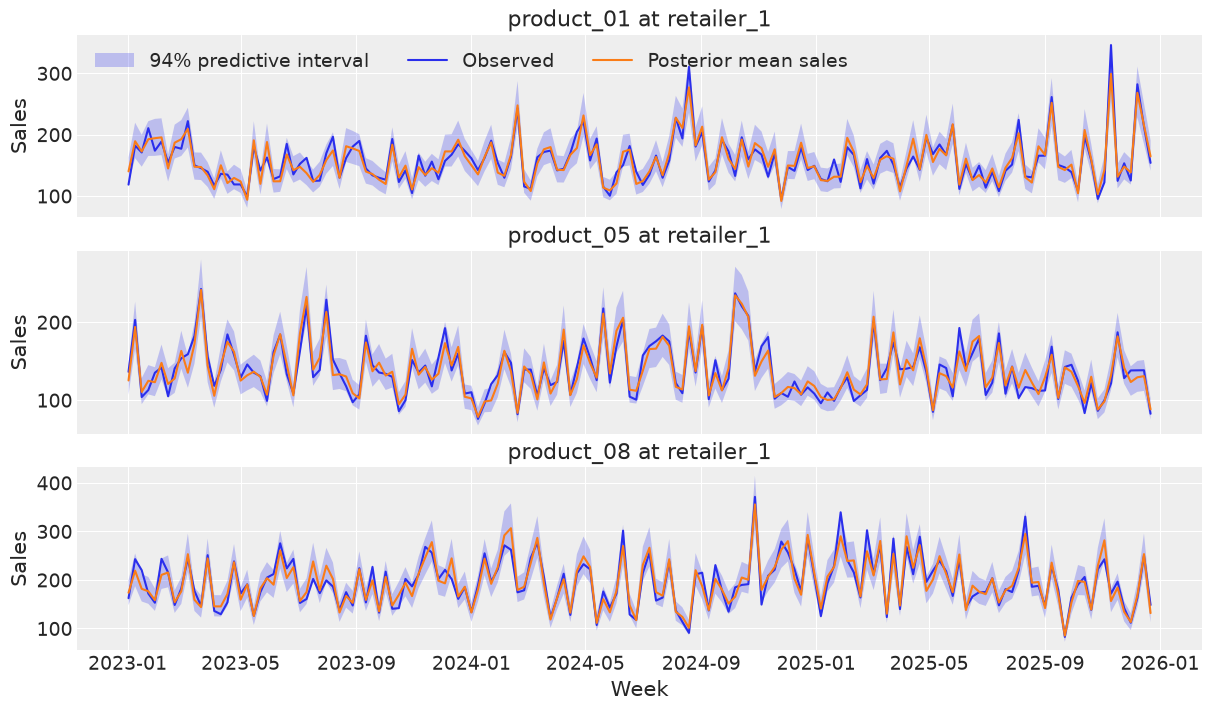

In [19]:
selected_products = [products[i] for i in (0, 4, 7)]
selection = {"product": selected_products, "retailer": retailers[0]}
interval = predicted_sales.sel(selection).quantile([0.03, 0.97], dim=("chain", "draw"))
mean_sales = conditional_mean.sel(selection).mean(("chain", "draw"))
fig, axes = plt.subplots(3, 1, sharex=True, layout="constrained")
for ax, product in zip(axes, selected_products, strict=True):
    band = interval.sel(product=product)
    ax.fill_between(
        dates,
        band.sel(quantile=0.03),
        band.sel(quantile=0.97),
        alpha=0.25,
        label="94% predictive interval",
    )
    ax.plot(dates, sales.sel(product=product, retailer=retailers[0]), label="Observed")
    ax.plot(dates, mean_sales.sel(product=product), label="Posterior mean sales")
    ax.set(title=f"{product} at {retailers[0]}", ylabel="Sales")
axes[0].legend(ncol=3)
axes[-1].set_xlabel("Week")
plt.show()

## 7. Interpret log effects as multipliers

A log effect of 0.1 multiplies conditional sales by `exp(0.1)`, approximately 1.105.
Read named effects at their native dimensions, without first duplicating them over products.
The table below averages each draw's multiplier over weeks, then summarizes posterior draws for one type and retailer.
These are conditional multipliers, not additive sales contributions or ROAS.

In [20]:
native = idata["posterior"]
media_multiplier = np.exp(native["media_log_effect"].sum("media_channel"))
search_multiplier = np.exp(native["search_log_effect"])
affiliate_multiplier = np.exp(native["affiliate_log_effect"].sum("affiliate_channel"))
multipliers = xr.Dataset(
    {
        "Saturating media": media_multiplier.sel(
            product_type="type_A", retailer=retailers[0]
        ),
        "Search": search_multiplier.sel(product_type="type_A"),
        "Affiliates": affiliate_multiplier.sel(
            product_type="type_A", retailer=retailers[0]
        ),
    }
).mean("date")
multipliers.quantile([0.03, 0.5, 0.97], dim=("chain", "draw")).to_dataframe().round(3)

,Saturating media,Search,Affiliates
quantile,,,
0.03,1.337,1.106,1.109
0.50,1.372,1.113,1.125
0.97,1.409,1.120,1.141


To calculate a channel's sales effect, compare full and channel-removed sales on paired posterior draws under an explicit history policy.
Exponentiating one channel's log effect does not allocate sales, and separate removal effects need not add to joint lift.
The [multiplicative walkthrough](terms_multiplicative_walkthrough.ipynb) explores attribution choices.

The composition pattern stays small even though the panel is not: keep native input dimensions, choose parameter dimensions, reduce channels explicitly, map types to products, and attach one likelihood.
New contiguous forecast weeks can use the same scaled inputs and membership matrix with `include_last_observations=True` to carry adstock history forward.

In [21]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Mon, 16 Nov 2026

Python implementation: CPython
Python version       : 3.14.0
IPython version      : 9.18.1

pymc_marketing: 1.4.0
pytensor      : 3.3.8

arviz         : 1.3.0
matplotlib    : 3.11.2
numpy         : 2.5.4
pandas        : 3.1.1
pymc_extras   : 0.16.0
pymc_marketing: 1.4.0
xarray        : 2026.9.0

Watermark: 2.6.0

